<a href="https://colab.research.google.com/github/felipe-suarez06/telecom-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello se trabajará con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.




---
## 🧩 Paso 1: Cargar y explorar



### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.


In [ ]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv") #completa el código
usage = pd.read_csv("/datasets/usage.csv") #completa el código

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.


In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.



In [ ]:
# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos
print()
print((users.isna().mean())*100) # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [ ]:
print(usage.isna().sum()) # cantidad de nulos para usage
print()
print((usage.isna().mean())) # Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
  
En users, city tiene 469 valores faltantes lo que representa el (11.725%) respecto al total de valores. Recomendaría investigar e imputar con la moda o dejarlo como nulo, ya que la proporción es moderada y no justifica eliminar la columna.

En users, churn_date tiene 3,534 valores faltantes (88.350%). No los imputaría ni eliminaría la columna, porque probablemente el usuario sigue activo y no ha cancelado; conviene conservar los nulos y, si es necesario, crear una variable indicadora de abandono.

En usage, date tiene 50 valores faltantes (0.125%). Al ser una proporción mínima, recomendaría eliminar esas filas si la fecha es necesaria para el análisis, o dejarlas como nulas si no afecta los cálculos.

En usage, duration tiene 22,076 valores faltantes (55.190%). Primero investigaría si los nulos corresponden a tipos de uso donde la duración no aplica, como mensajes; en ese caso, los dejaría como nulos y analizaría la columna según type, sin imputar de forma general.

En usage, length tiene 17,896 valores faltantes (44.740%). También comprobaría su relación con type; si solo aplica a mensajes, conservaría los nulos estructurales y no imputaría valores para llamadas u otros eventos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.


In [ ]:
# explorar columnas numéricas de users
print(round(users[["user_id","age"]].describe(),2))

users[["user_id","age"]].median()

        user_id      age
count   4000.00  4000.00
mean   11999.50    33.74
std     1154.84   123.23
min    10000.00  -999.00
25%    10999.75    32.00
50%    11999.50    47.00
75%    12999.25    63.00
max    13999.00    79.00


user_id    11999.5
age           47.0
dtype: float64

  La columna user_id es un identificador no mide nada, por lo que se ignora las estadísticas de la columna.
- La columna `age`
  Tiene una dispersión muy grande 123, indicando que un valor lo está jalando hacia arriba, en este caso se ve un valor minimo = -999 (sentinel)

In [ ]:
# explorar columnas numéricas de usage
print(round(usage[["id","user_id"]].describe(),2))

usage[["id","user_id"]].median()

             id   user_id
count  40000.00  40000.00
mean   20000.50  12002.41
std    11547.15   1157.28
min        1.00  10000.00
25%    10000.75  10996.00
50%    20000.50  12013.00
75%    30000.25  13005.00
max    40000.00  13999.00


id         20000.5
user_id    12013.0
dtype: float64

- Las columnas `id` y `user_id`
- Las columnas son identificadores no miden nada, por lo que se ignora las estadísticas de la columna. No tienen datos anormales.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(col)
    print(users[col].unique())

users[["city", "plan"]].value_counts()

city
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
plan
['Basico' 'Premium']


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

- La columna `city` ... presenta combinación de mayúsculas y minusculas, datos vacios "nan" y datos desconocidos representados con el signo "?"
- La columna `plan` ... solo presenta dos datos, nada anormal

In [ ]:
# explorar columna categórica de usage

# completa el código

print(usage['type'].unique())

usage['type'].value_counts()

['call' 'text']


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...
Solo presenta dos datos, nada anormal

**Valores inválidos o sentinels**  
- ¿En qué columnas se encuentran valores inválidos o sentinels?
  
  En las columna numérica "users.age" y la categórica "users.city"

- ¿Qué acción se tomaría?
  
  Para age, con -999, reemplazar por NaN e imputar con la mediana (que es más robusta a outliers que la media).
  Para city, reemplazar "?" por nan e imputar con la moda. Se toma esta decisión debido a que con esta imputación, en total serían 96 nan lo que representa una proporción del 2.4% respecto al total.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.


In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors = "coerce") # completa el código
users["reg_date"]

0      2022-01-01 00:00:00.000000000
1      2022-01-01 06:34:17.914478619
2      2022-01-01 13:08:35.828957239
3      2022-01-01 19:42:53.743435858
4      2022-01-02 02:17:11.657914478
                    ...             
3995   2024-12-29 21:42:48.342085520
3996   2024-12-30 04:17:06.256564144
3997   2024-12-30 10:51:24.171042768
3998   2024-12-30 17:25:42.085521392
3999   2024-12-31 00:00:00.000000000
Name: reg_date, Length: 4000, dtype: datetime64[ns]

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce") # completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users["reg_date"].dt.year.unique())
users["reg_date"].dt.year.value_counts()

[2022 2026 2023 2024]


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`,seven 40 fechas futuras (2026)

In [ ]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year.unique()

array([2024.,   nan])

En `date`,se ven valores vacios

**Fechas fuera de rango**  

  aparecen fechas del 2026 los cuales representan la proporción del 1 % respecto al total
  
- ¿Qué harías con ellas?

  eliminarlas

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

In [ ]:
# Reemplazar -999 por la mediana de age
print("casos donde la edad es -999:",users["age"].isin([-999]).sum())
age_mediana = users["age"].median()
print("mediana:", age_mediana)

users['age'] = users["age"].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


casos donde la edad es -999: 55
mediana: 47.0


count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

##

In [ ]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
users["city"]

0       Medellín
1           <NA>
2           CDMX
3         Bogotá
4            GDL
          ...   
3995    Medellín
3996    Medellín
3997      Bogotá
3998      Bogotá
3999      Bogotá
Name: city, Length: 4000, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[pd.to_datetime(users["reg_date"], errors = "coerce").dt.year == 2026, "reg_date"]= pd.NaT

# Verificar cambios

users["reg_date"].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().groupby(usage["type"]).mean().sort_values(ascending=False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).mean().sort_values(ascending=False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

La ausencia de valores en duration y length no es aleatoria: depende completamente de la columna type. Si type es "call", falta length; si es "text", falta duration. Es una relación perfectamente explicable con una variable observable, que es justamente la definición de MAR.`

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas




# Agrupar información por usuario
usage_agg = usage.groupby(["user_id"]).sum().reset_index()



# observar resultado
usage_agg.head(3)

,user_id,id,duration,length,is_text,is_call
0,10000,236778,23.70,258.0,7,3
1,10001,296458,33.18,226.0,5,10
2,10002,111444,10.74,225.0,5,2


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas","duration": "cant_minutos_llamada",})
# observar resultado
usage_agg.head(3)

,user_id,id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,236778,23.70,258.0,7,3
1,10001,296458,33.18,226.0,5,10
2,10002,111444,10.74,225.0,5,2


In [ ]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge( usage_agg, on="user_id", how="left")

user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,236778.0,23.70,258.0,7.0,3.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,296458.0,33.18,226.0,5.0,10.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,111444.0,10.74,225.0,5.0,2.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,289686.0,8.99,530.0,11.0,3.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,199943.0,8.01,229.0,4.0,3.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize = True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.




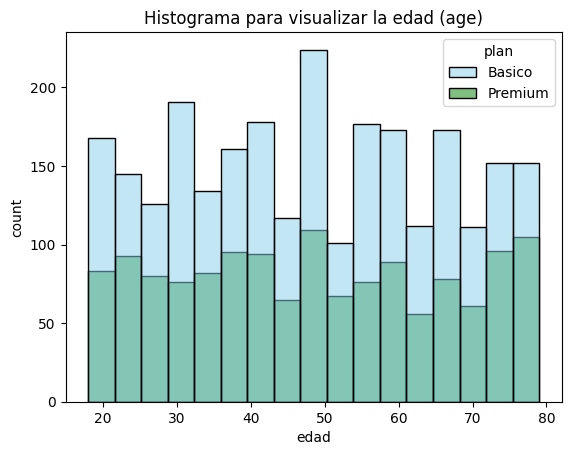

In [ ]:
# Histograma para visualizar la edad (age)


sns.histplot(data= user_profile ,x= "age",hue='plan',palette=['skyblue','green'])
plt.title("Histograma para visualizar la edad (age)")
plt.xlabel("edad")
plt.ylabel("count")
plt.show()



💡Insights:
"la edad no es un buen criterio para diferenciar el tipo de producto que se ofrece a cada cliente, porque los clientes de diferentes edades compran lo mismo".
Y dado que la mayoría de los clientes (65%) elige el plan Básico independientemente de su edad, las estrategias de marketing para promover el plan Premium no deberían segmentarse por edad, sino buscar otros factores (como uso de datos, minutos o mensajes).

- Distribución ... se aprecia una distribución simétrica

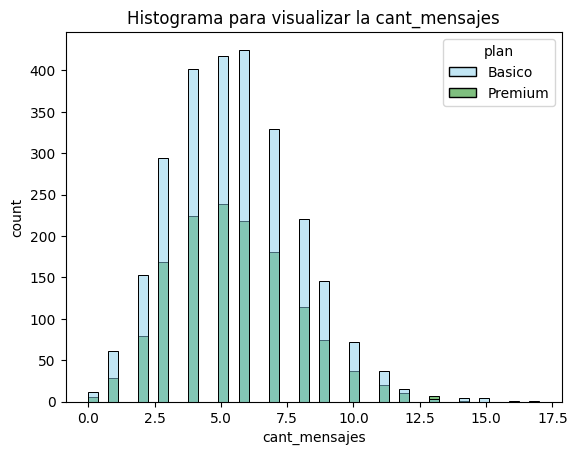

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data= user_profile,x="cant_mensajes", hue="plan",palette=['skyblue','green'])
plt.title("Histograma para visualizar la cant_mensajes")
plt.xlabel("cant_mensajes")
plt.ylabel("count")
plt.show()

💡Insights:
La distribución de cant_mensajes está sesgada a la derecha, con outliers que envían una cantidad de mensajes muy por encima del promedio, lo cual se confirma con la gran diferencia entre la media y el máximo observada en .describe().

- Distribución: sesgada a la derecha (right-skewed)

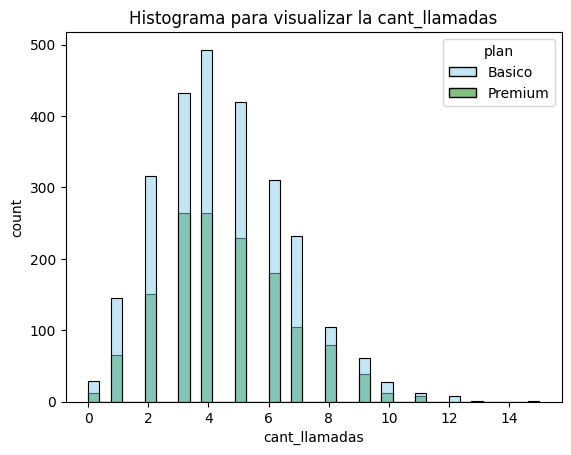

In [ ]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data = user_profile, x= "cant_llamadas", hue= "plan", palette=['skyblue','green'])
plt.title("Histograma para visualizar la cant_llamadas")
plt.xlabel("cant_llamadas")
plt.ylabel("count")
plt.show()


💡Insights:
- La distribución de cant_llamadas está sesgada a la derecha, con outliers que realizan un número de llamadas muy por encima del promedio, lo cual se confirma con la gran diferencia entre la media y el máximo observada en .describe().
    
- Distribución: sesgada a la derecha (right-skewed)


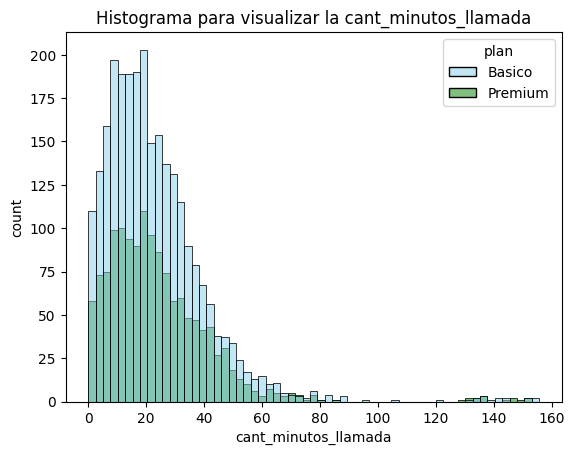

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data= user_profile, x= "cant_minutos_llamada", hue="plan", palette=['skyblue','green'])
plt.title("Histograma para visualizar la cant_minutos_llamada")
plt.xlabel("cant_minutos_llamada")
plt.ylabel("count")
plt.show()

💡Insights:

- La distribución de cant_minutos_llamada está sesgada a la derecha, con outliers que realizan llamadas con duración muy por encima del promedio, lo cual se confirma con la gran diferencia entre la media y el máximo observada en .describe().
  
- Distribución: sesgada a la derecha (right-skewed)


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

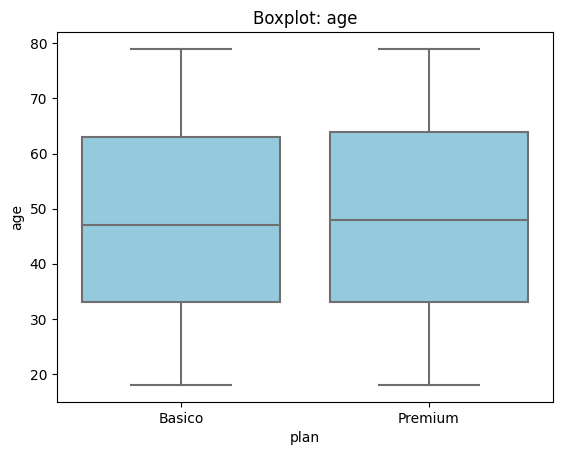

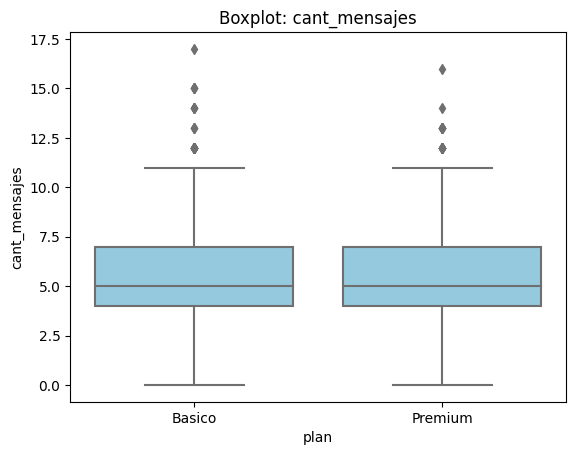

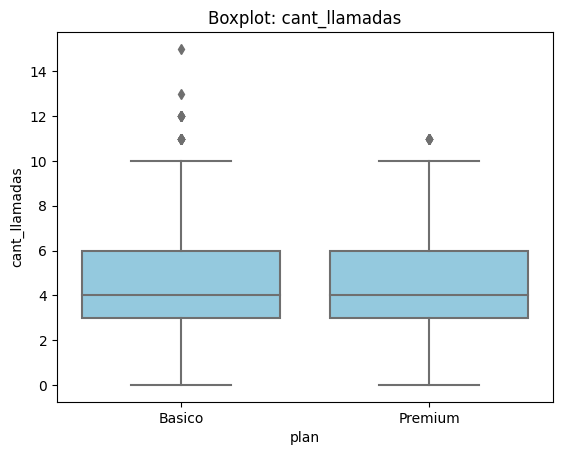

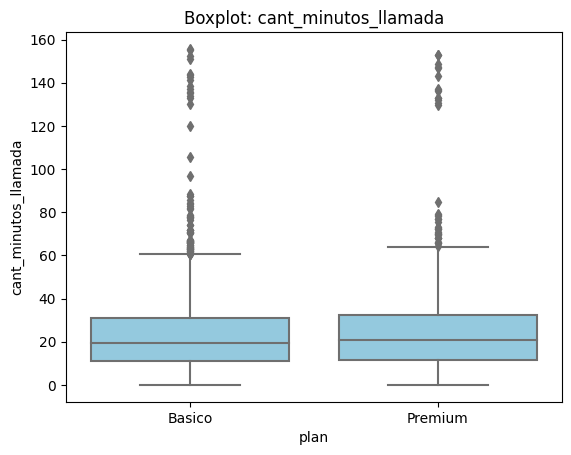

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data = user_profile, x= "plan", y=col, color= "skyblue")
    plt.title(f'Boxplot: {col}')
    plt.xlabel("plan")
    plt.ylabel(col)
    plt.show()



💡Insights:
- Age: ...(no presenta outliers, la mediana de edad es ligeramente mayor en Premium que en Básico
- cant_mensajes: ...(presenta outliers altos, se puede apreciar que en el plan básico se presentan más outliers)
- cant_llamadas: ...(presenta outliers altos,se puede apreciar una gran similitud entre las cajas, aunque en el plan básico hay usuarios que realizan más llamadas en comparación con el promedio, lo que se traduciría como outliers altos)
- cant_minutos_llamada: ...(se aprecia que la caja de premium es ligeramente más grande que la de básico, la caja de básico presenta muchos outliers muy altos, se puede apreciar que en este plan hay usuarios que realizan llamadas más prolongadas, lo que se traduciría como outliers altos)



In [ ]:

# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
     Q3 = user_profile[col].quantile(0.75)
     Q1 = user_profile[col].quantile(0.25)
     IQR= Q3-Q1
     upper = Q3 + 1.5*IQR
     print(f"{col}, {upper}")





age, 108.0
cant_mensajes, 11.5
cant_llamadas, 10.5
cant_minutos_llamada, 61.8575


In [ ]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: mantener o no outliers, por qué?
- sí mantenerlos, aunque el límite superior es 11.5 y el máximo real es 17 mensajes, si es plausible que un usuario mande por encima del promedio
- cant_llamadas: mantener o no outliers, por qué?
- sí mantenerlos, aunque el límite superior es 10.5 y el máximo real es 15 mensajes, si es plausible que un usuario llame más veces que el promedio
- cant_minutos_llamada: mantener o no outliers, por qué?
- sí mantenerlos, aunque el límite superior es 61.86 y el máximo real es 155.69 minutos, si es plausible que un usuario tenga llamadas más prolongadas que el promedio, aproximadamente 155 minutos equivaldría a 2.5 horas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

In [ ]:
# Crear columna grupo_uso
def clasificar_usuario(fila):
    if fila["cant_llamadas"] < 5 and fila["cant_mensajes"] < 5:
        return "Bajo uso"
    elif fila["cant_llamadas"] < 10 and fila["cant_mensajes"] < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile["grupo_uso"] = user_profile.apply(clasificar_usuario, axis=1)

In [ ]:
# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,236778.0,23.70,258.0,7.0,3.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,296458.0,33.18,226.0,5.0,10.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,111444.0,10.74,225.0,5.0,2.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,289686.0,8.99,530.0,11.0,3.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,199943.0,8.01,229.0,4.0,3.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.


In [ ]:
# Crear columna grupo_edad
def segmentacion_por_edad (fila):
    if fila["age"] < 30:
        return "Joven"
    elif fila["age"] < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"
user_profile["grupo_edad"] = user_profile.apply(segmentacion_por_edad, axis = 1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,236778.0,23.70,258.0,7.0,3.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,296458.0,33.18,226.0,5.0,10.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,111444.0,10.74,225.0,5.0,2.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,289686.0,8.99,530.0,11.0,3.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,199943.0,8.01,229.0,4.0,3.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

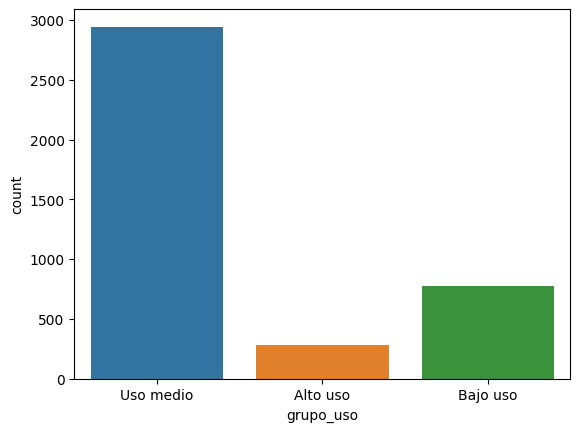

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso")

plt.show()

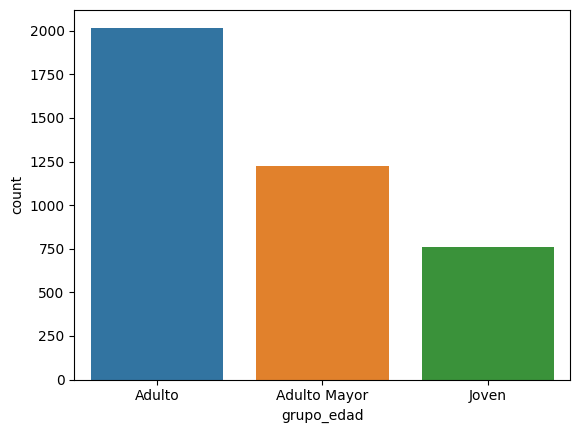

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data= user_profile, x= "grupo_edad")

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Los datos originales presentaban varios problemas de calidad:

- En users, la columna city tenía 469 valores nulos (11,73% de las filas).
- En usage (o el dataframe correspondiente), duration tenía 22076 nulos (55,19%)
  y length tenía 17896 nulos (44,74%), posiblemente debido a un problema en el
  registro de datos (missing at random).
- En users, age presentaba 55 valores sentinela -999 (1,3%), que fueron tratados
  como valores inválidos y reemplazados con la mediana.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
  se puede apreciar 3 segmentos: adulto, adulto mayor y joven, siendo el segmento de adultos el que presenta una mayor cantidad de usuarios, y en lo referente al uso predomina el uso medio.

  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
  Los segmentos de los adultos, adultos mayores y los que tienen un uso medio.

  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Se presentaron valores atípicos en la cantidad de mensajes, cantidad de llamadas y duración de llamadas, en la parte del negocio, puede implicar que los usuarios que sobrepasan el promedio sean cuentas corporativas.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

El segmento de "alto uso" necesitaría un plan con más minutos/datos de los que se ofrecen los planes actuales.
El segmento de "bajo uso" está pagando de más por un plan que no aprovecha.
Los outliers sugieren que falta un plan "premium" o un plan "básico" más ajustado.

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En users, la columna city tiene 469 valores nulos (11,73% de las filas).
- En usage , duration tenía 22076 nulos (55,19%).
  y length tenía 17896 nulos (44,74%).
- En users, age presentaba 55 valores sentinela -999 (1,3%).


🔍 **Segmentos por Edad**
- adulto
- adulto mayor
- joven

📊 **Segmentos por Nivel de Uso**
- bajo uso
- uso medio
- alto uso


➡️ Esto sugiere que ...
Hay usuarios con comportamiento atípico que podrían ser cuentas corporativas, errores de carga, o clientes muy intensivos que valdría la pena fidelizar.

💡 **Recomendaciones**
- El segmento de "alto uso" necesitaría un plan con más minutos/datos de los que ofrecen los planes actuales.
- El segmento de "bajo uso" está pagando de más por un plan que no aprovecha.
- Los outliers sugieren que falta un plan "premium" o un plan "básico" más ajustado.